<a href="https://colab.research.google.com/github/khalidkanane/waste-classification-mlp/blob/main/notebooks/waste_classification_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="background:linear-gradient(135deg,#0f766e 0%,#1d4ed8 60%,#6d28d9 100%);padding:34px 30px;border-radius:16px;color:#ffffff;">
<div style="font-size:13px;letter-spacing:4px;opacity:.85;">DEEP LEARNING · IMAGE CLASSIFICATION</div>
<h1 style="margin:10px 0 6px 0;color:#ffffff;border:none;">♻️ Waste Classification with an MLP</h1>
<div style="font-size:16px;opacity:.95;">Intelligent waste sorting on TrashNet — cardboard · glass · plastic</div>
</div>

---


---



| 🗂️ Dataset | 🖼️ Input | 🧠 Model | ⚙️ Optimizers | 🎯 Task |
|:--:|:--:|:--:|:--:|:--:|
| TrashNet (3 classes) | 64 × 64 RGB | MLP (Dense + Dropout) | SGD · RMSprop · Adam | 3-class classification |

## 🗺️ Project roadmap

| # | Step | What we do | Jump |
|:-:|------|------------|:----:|
| 1 | **Download TrashNet** | Set up the environment, download and extract the dataset | [Go ▸](#step1) |
| 2 | **Dataset inspection** | Count images, inspect samples and labels | [Go ▸](#step2) |
| 3 | **Data preprocessing** | Resize, normalize and split images | [Go ▸](#step3) |
| 4 | **MLP implementation** | Flatten, Dense, Dropout and Softmax | [Go ▸](#step4) |
| 5 | **Optimizer comparison** | SGD vs RMSprop vs Adam | [Go ▸](#step5) |
| 6 | **Evaluation** | Accuracy, loss curves and confusion matrix | [Go ▸](#step6) |
| 7 | **Final demonstration** | Predict new images and save the model | [Go ▸](#step7) |

After step 7, a short **wrap-up** summarises the results and the conclusion.

## 🎯 Problem definition

**Objective:** develop an AI model that recognizes waste materials from images, to help a recycling center sort them automatically.

The project relates to two tasks:

| Task | Goal | Suited architecture |
|------|------|---------------------|
| **Classification** | Recognize the type of waste (cardboard, glass, plastic) | MLP / CNN |
| **Object detection** | Find each object's position *and* type on a conveyor belt | CNN-based detector |

<div style="border-left:5px solid rgb(59,130,246);background:rgba(59,130,246,.12);padding:10px 16px;border-radius:6px;margin:10px 0;">
<b>💡 Scope of this notebook</b><br>
A traditional <b>MLP</b> is suitable for classifying an image of an <b>already-cropped</b> waste object. It is not the ideal architecture for detecting several objects and their positions on a conveyor-belt image — a CNN-based detector is more appropriate for that.
</div>

### Supervised learning in one example

In supervised learning every sample is a pair **(X<sub>i</sub>, y<sub>i</sub>)**:

| Element | Meaning | Example |
|---------|---------|---------|
| **X<sub>i</sub>** | Input | Image of a plastic bottle |
| **y<sub>i</sub>** | Expected output (label) | `plastic` |
| **ŷ<sub>i</sub>** | Model prediction | `plastic` → ✅ correct prediction |

<a id="step1"></a>
<div style="background:linear-gradient(135deg,#0f766e,#1d4ed8);padding:20px 26px;border-radius:14px;color:#ffffff;margin:10px 0;">
<div style="font-size:12px;letter-spacing:3px;opacity:.85;">STEP 1 OF 7 &nbsp;·&nbsp; ▰▱▱▱▱▱▱</div>
<h2 style="margin:6px 0 4px 0;color:#ffffff;border:none;">1 · Download TrashNet</h2>
<div style="opacity:.92;font-size:15px;">Download and extract the dataset.</div>
</div>

### 1.1 · Prepare the Python environment

Install the required libraries.

In [ ]:
# Cell 1: Install libraries

%pip install tensorflow matplotlib seaborn scikit-learn numpy pandas

### 1.2 · Import the libraries

In [ ]:
# Cell 2: Import libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### 1.3 · Download the dataset

We clone the official **TrashNet** repository. It contains `dataset-resized.zip`, the images resized to 512 × 384.

In [ ]:
!git clone https://github.com/garythung/trashnet.git

Cloning into 'trashnet'...
remote: Enumerating objects: 45, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 45 (delta 12), reused 6 (delta 6), pack-reused 27 (from 1)
Receiving objects: 100% (45/45), 40.64 MiB | 2.71 MiB/s, done.
Resolving deltas: 100% (14/14), done.


### 1.4 · Check the download

<div style="border-left:5px solid rgb(59,130,246);background:rgba(59,130,246,.12);padding:10px 16px;border-radius:6px;margin:10px 0;">
<b>💡 Extraction</b><br>
The archive `dataset-resized.zip` is extracted automatically at the start of the <b>next step</b> (the first cell of Step 2).
</div>

In [ ]:
from pathlib import Path
import os

DATASET_PATH = Path("/content/trashnet/data")

print("Dataset exists:", DATASET_PATH.exists())

print("Available classes:")
print(os.listdir(DATASET_PATH))

Dataset exists: True
Available classes:
['one-indexed-files-notrash_test.txt', 'constants.py', 'one-indexed-files-notrash_val.txt', 'one-indexed-files.txt', 'resize.py', 'one-indexed-files-notrash_train.txt', 'zero-indexed-files.txt', 'dataset-resized.zip']


<a id="step2"></a>
<div style="background:linear-gradient(135deg,#0f766e,#1d4ed8);padding:20px 26px;border-radius:14px;color:#ffffff;margin:10px 0;">
<div style="font-size:12px;letter-spacing:3px;opacity:.85;">STEP 2 OF 7 &nbsp;·&nbsp; ▰▰▱▱▱▱▱</div>
<h2 style="margin:6px 0 4px 0;color:#ffffff;border:none;">2 · Dataset inspection</h2>
<div style="opacity:.92;font-size:15px;">Count images, inspect samples and labels.</div>
</div>

### 2.1 · Extract the archive and count images per class

We keep **three classes** — `cardboard`, `glass`, `plastic` — and count the images in each one.

In [ ]:
import zipfile
import pandas as pd

zip_path = DATASET_PATH / "dataset-resized.zip"
extract_path = DATASET_PATH

# Unzip dataset if it hasn't been extracted yet
if zip_path.exists() and not (DATASET_PATH / "dataset-resized").exists():
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

# The dataset extracts into a subfolder named 'dataset-resized'
ACTUAL_DATA_PATH = DATASET_PATH / "dataset-resized"

CLASSES = ["cardboard", "glass", "plastic"]
data = []

for class_name in CLASSES:
    folder = ACTUAL_DATA_PATH / class_name
    if folder.exists():
        images = [
            f for f in folder.iterdir()
            if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]
    else:
        images = []

    data.append({
        "Class": class_name,
        "Number of images": len(images)
    })

df = pd.DataFrame(data)
display(df)
print("Total images:", df["Number of images"].sum())

Extracting dataset...


,Class,Number of images
0,cardboard,403
1,glass,501
2,plastic,482


Total images: 1386


### 2.2 · Visualize sample images

One example per class, to check that images and labels match.

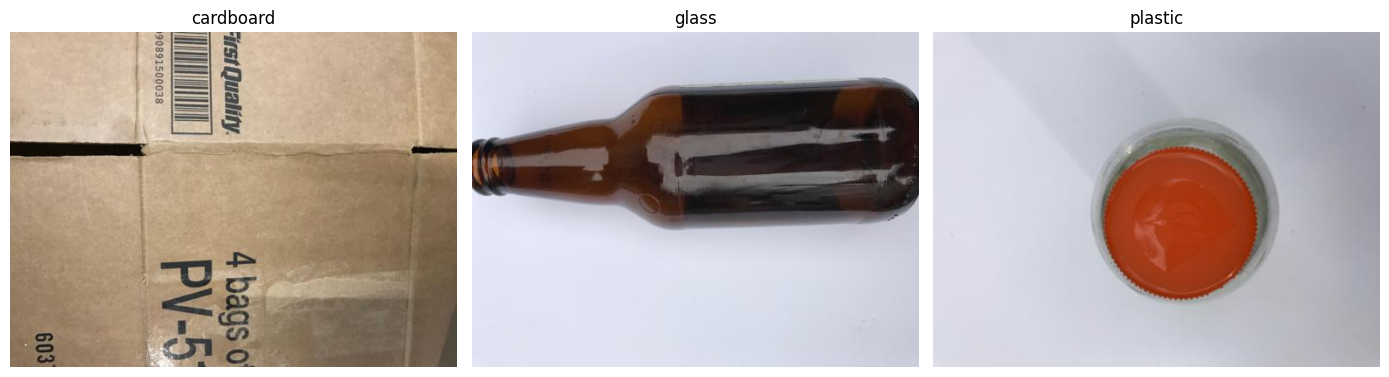

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for i, class_name in enumerate(CLASSES):
    # Use ACTUAL_DATA_PATH from the previous cell
    folder = ACTUAL_DATA_PATH / class_name

    image_files = list(folder.glob("*.jpg"))

    if image_files:
        img = Image.open(image_files[0])
        axes[i].imshow(img)
        axes[i].set_title(class_name)
        axes[i].axis("off")
    else:
        axes[i].text(0.5, 0.5, f"No images found\nin {class_name}", ha='center', va='center')
        axes[i].axis("off")

plt.tight_layout()
plt.show()

<a id="step3"></a>
<div style="background:linear-gradient(135deg,#0f766e,#1d4ed8);padding:20px 26px;border-radius:14px;color:#ffffff;margin:10px 0;">
<div style="font-size:12px;letter-spacing:3px;opacity:.85;">STEP 3 OF 7 &nbsp;·&nbsp; ▰▰▰▱▱▱▱</div>
<h2 style="margin:6px 0 4px 0;color:#ffffff;border:none;">3 · Data preprocessing</h2>
<div style="opacity:.92;font-size:15px;">Split, resize and normalize the images.</div>
</div>

### 3.1 · Split the dataset (Train / Validation / Test)

We use a **stratified** split so every subset keeps the same class proportions:

| Subset | Share | Role |
|--------|:-----:|------|
| **Train** | 70 % | Learn the weights |
| **Validation** | 15 % | Tune and compare models |
| **Test** | 15 % | Final, unbiased evaluation |

In [ ]:
from sklearn.model_selection import train_test_split
import shutil
from pathlib import Path

image_paths = []
labels = []

# The dataset extracts into a subfolder named 'dataset-resized'
ACTUAL_DATA_PATH = DATASET_PATH / "dataset-resized"

# Collect image paths and labels
for class_name in CLASSES:
    # Fix: use ACTUAL_DATA_PATH instead of DATASET_PATH
    folder = ACTUAL_DATA_PATH / class_name

    for img in folder.iterdir():

        if img.suffix.lower() in [".jpg", ".jpeg", ".png"]:

            image_paths.append(str(img))
            labels.append(class_name)


# Split 70% train and 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Split temporary data into 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)


# Create output directory from scratch
OUTPUT_PATH = Path("/content/waste_dataset")

if OUTPUT_PATH.exists():
    shutil.rmtree(OUTPUT_PATH)

for split in ["train", "val", "test"]:
    for class_name in CLASSES:

        (OUTPUT_PATH / split / class_name).mkdir(
            parents=True,
            exist_ok=True
        )


# Copy images into folders
splits = [
    ("train", X_train, y_train),
    ("val", X_val, y_val),
    ("test", X_test, y_test)
]

for split_name, paths, split_labels in splits:

    for path, label in zip(paths, split_labels):

        destination = (
            OUTPUT_PATH / split_name / label / Path(path).name
        )

        shutil.copy2(path, destination)


print("Dataset splitting completed!")

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Dataset splitting completed!
Training: 970
Validation: 208
Testing: 208


### 3.2 · Verify the class distribution

In [ ]:
for split in ["train", "val", "test"]:

    print(f"\n{split.upper()}")

    for class_name in CLASSES:

        folder = OUTPUT_PATH / split / class_name

        count = len(list(folder.glob("*")))

        print(class_name, ":", count)


TRAIN
cardboard : 282
glass : 351
plastic : 337

VAL
cardboard : 61
glass : 75
plastic : 72

TEST
cardboard : 60
glass : 75
plastic : 73


### 3.3 · Load the images and resize them

TensorFlow loads the folders as datasets. Every image is **resized to 64 × 64** and grouped in batches of 32.

In [ ]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    str(OUTPUT_PATH / "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(OUTPUT_PATH / "val"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    str(OUTPUT_PATH / "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Found 970 files belonging to 3 classes.
Found 208 files belonging to 3 classes.
Found 208 files belonging to 3 classes.
Classes: ['cardboard', 'glass', 'plastic']
Number of classes: 3


### 3.4 · Normalize the pixel values

A pixel initially has a value between 0 and 255. After dividing by 255, it lies between **0 and 1**:

$$128 / 255 \approx 0.502$$

The network trains more easily on small, consistently scaled inputs. We also add `prefetch` so data loading overlaps with training.

In [ ]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

<a id="step4"></a>
<div style="background:linear-gradient(135deg,#0f766e,#1d4ed8);padding:20px 26px;border-radius:14px;color:#ffffff;margin:10px 0;">
<div style="font-size:12px;letter-spacing:3px;opacity:.85;">STEP 4 OF 7 &nbsp;·&nbsp; ▰▰▰▰▱▱▱</div>
<h2 style="margin:6px 0 4px 0;color:#ffffff;border:none;">4 · MLP implementation</h2>
<div style="opacity:.92;font-size:15px;">Flatten, Dense, Dropout and Softmax.</div>
</div>

### 4.1 · Network architecture

| Layer | Output shape | Role |
|-------|:------------:|------|
| `Input` | 64 × 64 × 3 | RGB image |
| `Flatten` | 12 288 | Turns the image into one vector of pixels |
| `Dense(256, ReLU)` | 256 | First hidden layer |
| `Dropout(0.30)` | 256 | Regularization |
| `Dense(128, ReLU)` | 128 | Second hidden layer |
| `Dropout(0.20)` | 128 | Regularization |
| `Dense(3, Softmax)` | 3 | Probability of each class |

<div style="border-left:5px solid rgb(59,130,246);background:rgba(59,130,246,.12);padding:10px 16px;border-radius:6px;margin:10px 0;">
<b>💡 Dropout switch</b><br>
`create_mlp(use_dropout=True)` can build the same network **without** Dropout (`use_dropout=False`), which makes it easy to test the effect of Dropout.
</div>

Implement the **MLP**

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def create_mlp(use_dropout=True):

    model = keras.Sequential([

        layers.Input(shape=(64, 64, 3)),

        layers.Flatten(),

        layers.Dense(256, activation="relu"),

        layers.Dropout(0.30) if use_dropout
        else layers.Activation("linear"),

        layers.Dense(128, activation="relu"),

        layers.Dropout(0.20) if use_dropout
        else layers.Activation("linear"),

        layers.Dense(NUM_CLASSES, activation="softmax")

    ])

    return model


model = create_mlp()

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,179,267 (12.13 MB)

 Trainable params: 3,179,267 (12.13 MB)

 Non-trainable params: 0 (0.00 B)

<a id="step5"></a>
<div style="background:linear-gradient(135deg,#0f766e,#1d4ed8);padding:20px 26px;border-radius:14px;color:#ffffff;margin:10px 0;">
<div style="font-size:12px;letter-spacing:3px;opacity:.85;">STEP 5 OF 7 &nbsp;·&nbsp; ▰▰▰▰▰▱▱</div>
<h2 style="margin:6px 0 4px 0;color:#ffffff;border:none;">5 · Optimizer comparison</h2>
<div style="opacity:.92;font-size:15px;">SGD vs RMSprop vs Adam.</div>
</div>

### 5.1 · The three optimizers

| Optimizer | How it works | Advantage | Settings used |
|-----------|--------------|-----------|---------------|
| **SGD + momentum** | Updates weights along the gradient and keeps a "velocity" from previous steps | Simple, often generalizes well | `lr=0.01`, `momentum=0.9` |
| **RMSprop** | Adapts the step size of each weight using a moving average of squared gradients | Handles gradients of different scales | `lr=0.001` |
| **Adam** | Combines momentum with adaptive step sizes | Fast, robust default | `lr=0.001` |

**Configure the optimizers**
Define optimizers

In [ ]:
def get_optimizer(name):

    if name == "SGD":
        return keras.optimizers.SGD(
            learning_rate=0.01,
            momentum=0.9
        )

    elif name == "RMSprop":
        return keras.optimizers.RMSprop(
            learning_rate=0.001
        )

    elif name == "Adam":
        return keras.optimizers.Adam(
            learning_rate=0.001
        )

### 5.2 · Train the three models

<div style="border-left:5px solid rgb(245,158,11);background:rgba(245,158,11,.12);padding:10px 16px;border-radius:6px;margin:10px 0;">
<b>⚠️ Fair comparison</b><br>
Each optimizer trains a <b>newly initialized</b> MLP, with the same architecture, data, batch size and maximum number of epochs (25). Reusing one model would bias the comparison.
</div>

<div style="border-left:5px solid rgb(59,130,246);background:rgba(59,130,246,.12);padding:10px 16px;border-radius:6px;margin:10px 0;">
<b>💡 Why EarlyStopping?</b><br>
If the validation loss does not improve for <b>5 consecutive epochs</b>, training stops and the best weights are restored. This avoids useless training and limits overfitting.
</div>

In [ ]:
EPOCHS = 25

optimizers_names = ["SGD", "RMSprop", "Adam"]

histories = {}
trained_models = {}
results = {}

for optimizer_name in optimizers_names:

    print("\n" + "="*50)
    print("Training with:", optimizer_name)
    print("="*50)

    # Create a fresh model
    model = create_mlp()

    # Compile
    model.compile(
        optimizer=get_optimizer(optimizer_name),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Early stopping
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    # Train
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[early_stopping],
        verbose=1
    )

    histories[optimizer_name] = history
    trained_models[optimizer_name] = model

    # Evaluate on validation data
    val_loss, val_accuracy = model.evaluate(
        val_ds,
        verbose=0
    )

    results[optimizer_name] = {
        "Validation Loss": val_loss,
        "Validation Accuracy": val_accuracy,
        "Epochs": len(history.history["loss"])
    }

print("\nAll training experiments completed!")


Training with: SGD
Epoch 1/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step - accuracy: 0.3639 - loss: 1.3625 - val_accuracy: 0.3462 - val_loss: 1.0692
Epoch 2/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.4258 - loss: 1.0491 - val_accuracy: 0.3702 - val_loss: 1.0571
Epoch 3/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.4557 - loss: 1.0208 - val_accuracy: 0.5433 - val_loss: 0.9137
Epoch 4/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.5010 - loss: 0.9539 - val_accuracy: 0.6250 - val_loss: 0.8614
Epoch 5/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.4722 - loss: 0.9566 - val_accuracy: 0.6538 - val_loss: 0.8874
Epoch 6/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.4804 - loss: 0.9441 - val_accuracy: 0.6202 - val_loss: 0.8736
Epoch 7/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.4825 - loss: 0.9626 - val_accuracy: 0.6202 - val_loss: 0.8183
Epoch 8/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.4742 - loss: 0.9566 - val

### 5.3 · Results table

In [ ]:
results_df = pd.DataFrame(results).T

display(results_df.round(4))

,Validation Loss,Validation Accuracy,Epochs
SGD,0.8183,0.6202,12.0
RMSprop,1.0948,0.3606,19.0
Adam,0.8437,0.5481,11.0


<a id="step6"></a>
<div style="background:linear-gradient(135deg,#0f766e,#1d4ed8);padding:20px 26px;border-radius:14px;color:#ffffff;margin:10px 0;">
<div style="font-size:12px;letter-spacing:3px;opacity:.85;">STEP 6 OF 7 &nbsp;·&nbsp; ▰▰▰▰▰▰▱</div>
<h2 style="margin:6px 0 4px 0;color:#ffffff;border:none;">6 · Evaluation</h2>
<div style="opacity:.92;font-size:15px;">Accuracy, loss curves and confusion matrix.</div>
</div>

### 6.1 · Loss curves

The **loss** measures how far the predictions are from the correct answers.

- 📉 Lower loss = better predictions.
- 📉 Decreasing loss = the model is learning.
- 📈 Validation loss rising while training loss falls = possible **overfitting**.

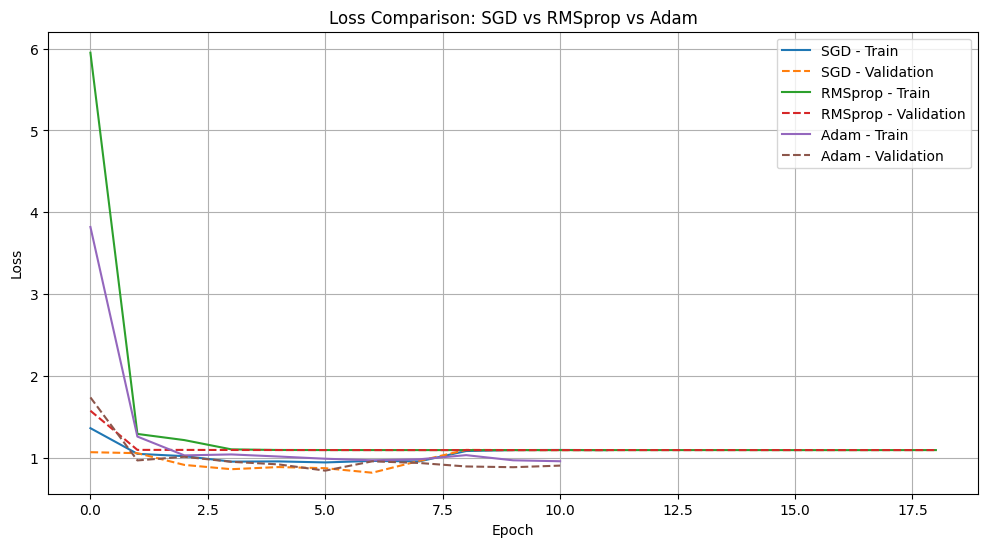

In [ ]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history["loss"],
        label=f"{name} - Train"
    )

    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.title("Loss Comparison: SGD vs RMSprop vs Adam")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

### 6.2 · Accuracy curves

The **accuracy** is the share of correctly classified images:

$$\text{Accuracy} = \frac{\text{Correct predictions}}{\text{Total predictions}}$$

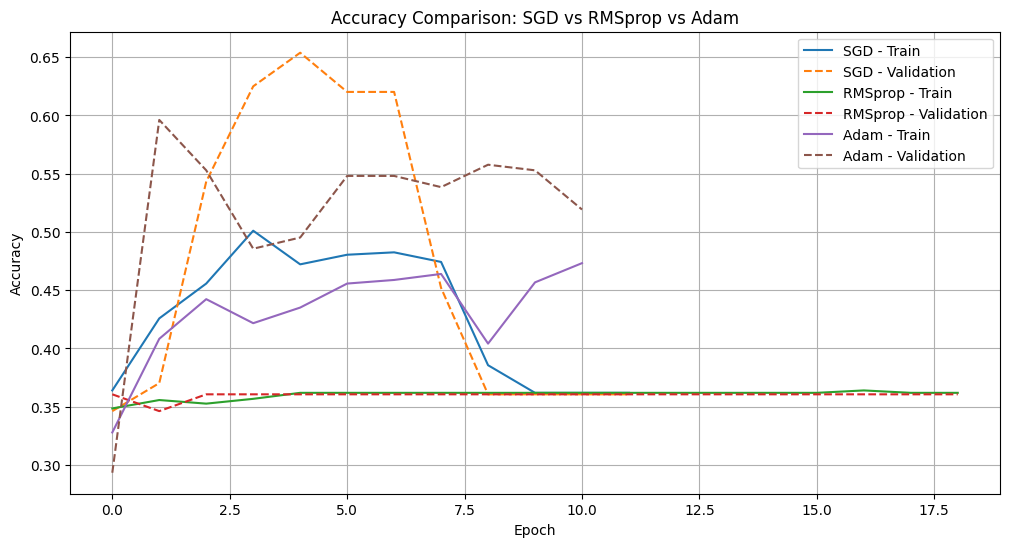

In [ ]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history["accuracy"],
        label=f"{name} - Train"
    )

    plt.plot(
        history.history["val_accuracy"],
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.title("Accuracy Comparison: SGD vs RMSprop vs Adam")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)
plt.show()

### 6.3 · Select the best optimizer

<div style="border-left:5px solid rgb(16,185,129);background:rgba(16,185,129,.12);padding:10px 16px;border-radius:6px;margin:10px 0;">
<b>✅ Selection rule</b><br>
The model is chosen on <b>validation</b> accuracy, never on test accuracy, so the test set stays truly unseen.
</div>

In [ ]:
best_optimizer = results_df["Validation Accuracy"].idxmax()

best_model = trained_models[best_optimizer]

print("Best optimizer:", best_optimizer)

print(
    "Validation accuracy:",
    round(
        results_df.loc[best_optimizer, "Validation Accuracy"] * 100,
        2
    ),
    "%"
)

Best optimizer: SGD
Validation accuracy: 62.02 %


### 6.4 · Best model

The selected model is stored in `best_model` and used for all the following evaluations.

In [ ]:
best_optimizer = results_df["Validation Accuracy"].idxmax()

best_model = trained_models[best_optimizer]

print("Best optimizer:", best_optimizer)

print(
    "Validation accuracy:",
    round(
        results_df.loc[best_optimizer, "Validation Accuracy"] * 100,
        2
    ),
    "%"
)

Best optimizer: SGD
Validation accuracy: 62.02 %


### 6.5 · Final accuracy on the test set

We now evaluate the selected model on **unseen** test images.

In [ ]:
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("Best optimizer:", best_optimizer)
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5721 - loss: 0.8531
Best optimizer: SGD
Test Loss: 0.8531
Test Accuracy: 57.21 %


### 6.6 · Confusion matrix

A confusion matrix shows **which waste categories are mixed up**, for example cardboard predicted as plastic, or glass predicted as plastic.

**Generate the predictions**

For example:
- Cardboard classified as Plastic.
- Glass classified as Plastic.
- Plastic classified as Glass.



In [ ]:
y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

**Plot confusion matrix**

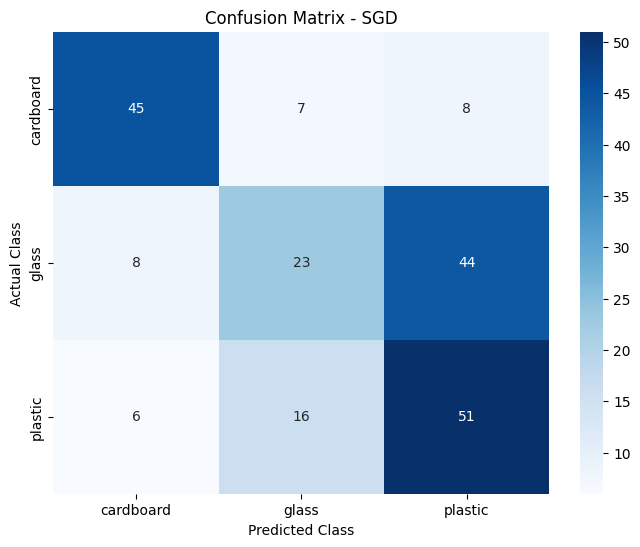

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(NUM_CLASSES)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title(f"Confusion Matrix - {best_optimizer}")

plt.show()

<div style="border-left:5px solid rgb(59,130,246);background:rgba(59,130,246,.12);padding:10px 16px;border-radius:6px;margin:10px 0;">
<b>💡 How to read it</b><br>
<b>Rows</b> = actual classes · <b>Columns</b> = predicted classes · <b>Diagonal</b> = correct predictions · <b>Off-diagonal</b> = errors.
</div>

> In this run, **44 of the 75 glass images** were predicted as plastic, and 16 plastic images as glass: these two classes are the hardest to separate.

### 6.7 · Classification report

**Precision**, **Recall** and **F1-score** for each class.

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        labels=range(NUM_CLASSES),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

   cardboard       0.76      0.75      0.76        60
       glass       0.50      0.31      0.38        75
     plastic       0.50      0.70      0.58        73

    accuracy                           0.57       208
   macro avg       0.59      0.59      0.57       208
weighted avg       0.57      0.57      0.56       208



### 6.8 · Convergence speed

*Which optimizer converges the fastest?* With `EarlyStopping(patience=5)`, the best epoch is roughly the number of epochs run minus 5.

| Optimizer | Epochs run | Best epoch (≈) | Validation loss | Validation accuracy |
|-----------|:----------:|:--------------:|:---------------:|:-------------------:|
| **SGD** | 12 | 7 | 0.8183 | 62.02 % |
| **RMSprop** | 19 | 14 | 1.0948 | 36.06 % |
| **Adam** | 11 | 6 | 0.8437 | 54.81 % |

*(Values from the recorded run; see the table in 5.3.)*

### 6.9 · Generalization gap

The gap is the difference between the best training accuracy and the best validation accuracy.

Generalization **gap**

In [ ]:
for name, history in histories.items():

    train_acc = max(history.history["accuracy"])

    val_acc = max(history.history["val_accuracy"])

    gap = abs(train_acc - val_acc)

    print(f"\n{name}")
    print("Training accuracy:", round(train_acc * 100, 2), "%")
    print("Validation accuracy:", round(val_acc * 100, 2), "%")
    print("Generalization gap:", round(gap * 100, 2), "%")


SGD
Training accuracy: 50.1 %
Validation accuracy: 65.38 %
Generalization gap: 15.28 %

RMSprop
Training accuracy: 36.39 %
Validation accuracy: 36.06 %
Generalization gap: 0.33 %

Adam
Training accuracy: 47.32 %
Validation accuracy: 59.62 %
Generalization gap: 12.3 %


<div style="border-left:5px solid rgb(59,130,246);background:rgba(59,130,246,.12);padding:10px 16px;border-radius:6px;margin:10px 0;">
<b>💡 Interpretation</b><br>
A <b>small gap</b> can mean better generalization, a <b>large gap</b> possible overfitting, and a <b>high validation accuracy</b> good performance on unseen images.
</div>

<div style="border-left:5px solid rgb(245,158,11);background:rgba(245,158,11,.12);padding:10px 16px;border-radius:6px;margin:10px 0;">
<b>⚠️ Reading the numbers carefully</b><br>
Here the validation accuracy is <i>higher</i> than the training accuracy: Dropout is active during training (not during validation), and each value is the best epoch of its own curve. The real warning sign is different — training accuracy stays low (≤ 50 %), so the models <b>underfit</b>.
</div>

<a id="step7"></a>
<div style="background:linear-gradient(135deg,#0f766e,#1d4ed8);padding:20px 26px;border-radius:14px;color:#ffffff;margin:10px 0;">
<div style="font-size:12px;letter-spacing:3px;opacity:.85;">STEP 7 OF 7 &nbsp;·&nbsp; ▰▰▰▰▰▰▰</div>
<h2 style="margin:6px 0 4px 0;color:#ffffff;border:none;">7 · Final demonstration</h2>
<div style="opacity:.92;font-size:15px;">Predict new images and save the model.</div>
</div>

### 7.1 · Upload a new image

Upload any waste photo from your computer (Colab).

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 360_F_288594648_o9lRdsdVCXWnhP2mZLZMNcYRUVvz51uj.jpg to 360_F_288594648_o9lRdsdVCXWnhP2mZLZMNcYRUVvz51uj.jpg


### 7.2 · Predict its class

The image is resized to 64 × 64, normalized exactly like the training data, and passed to the best model.

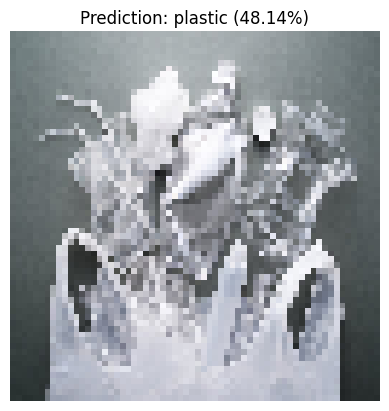

Predicted class: plastic
Confidence: 48.14 %


In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

image_path = list(uploaded.keys())[0]

img = load_img(
    image_path,
    target_size=IMG_SIZE
)

img_array = img_to_array(img) / 255.0

img_array = np.expand_dims(img_array, axis=0)

prediction = best_model.predict(img_array, verbose=0)

predicted_index = np.argmax(prediction[0])

predicted_class = class_names[predicted_index]

confidence = prediction[0][predicted_index] * 100

plt.imshow(img)
plt.axis("off")
plt.title(
    f"Prediction: {predicted_class} ({confidence:.2f}%)"
)
plt.show()

print("Predicted class:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

### 7.3 · Connect Google Drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


### 7.4 · Save the trained model

The best model is saved in the native Keras format (`.keras`), ready to be reloaded for later predictions.

In [ ]:
MODEL_PATH = (
    "/content/drive/MyDrive/"
    "waste_classification_mlp.keras"
)

best_model.save(MODEL_PATH)

print("Model saved:", MODEL_PATH)

Model saved: /content/drive/MyDrive/waste_classification_mlp.keras


<div style="background:linear-gradient(135deg,#0f766e,#1d4ed8);padding:20px 26px;border-radius:14px;color:#ffffff;margin:10px 0;">
<div style="font-size:12px;letter-spacing:3px;opacity:.85;">WRAP-UP</div>
<h2 style="margin:6px 0 4px 0;color:#ffffff;border:none;"> Analysis of the results</h2>
<div style="opacity:.92;font-size:15px;">What the experiments tell us about an MLP on waste images.</div>
</div>

### 1 · Optimizer comparison

Three optimizers (SGD, RMSprop, Adam) were compared with the same MLP architecture and the same data.

- **SGD with momentum** gave the best result: validation accuracy **62.02 %** and the lowest validation loss (0.8183).
- **Adam** converged fastest (best epoch ≈ 6) but ended lower: **54.81 %**.
- **RMSprop** performed worst: **36.06 %**, which equals the share of the largest class (glass, 75/208) and suggests it did not learn to discriminate between classes.

### 2 · Generalization

The selected SGD model reaches **57.21 %** on the unseen test set (validation: 62.02 %). The drop is expected on small validation/test sets of 208 images. The model generalizes to new images, but modestly.

### 3 · Effect of Dropout

Dropout reduces overfitting by randomly switching off neurons during training. This notebook trains the MLP **with** Dropout only; to measure its effect, retrain with `create_mlp(use_dropout=False)` and compare the validation accuracy of both versions.

### 4 · Confusion matrix

The hardest classes to separate are **glass** and **plastic** (glass recall: 0.31, plastic precision: 0.50). Their color, transparency, shape and texture can look very similar once the image is flattened to 64 × 64 pixels. **Cardboard** is the easiest class (F1 = 0.76).

### 5 · Conclusion

We designed and trained a multilayer perceptron to classify three waste categories: cardboard, glass and plastic. Comparing optimizers showed their influence on convergence and generalization, with SGD + momentum as the best choice here.

However, an MLP on flattened pixels ignores the **spatial structure** of images, which limits its accuracy (training accuracy never exceeds 50 %). To get closer to an industrial sorting system, a **CNN** — and, for conveyor belts, a CNN-based object detector — is the natural next step.